### DMW: Kubische Gleichungen, komplexe Zahlen und algebraische Kurven - Übungen

Dieses Notebook gehört zum Wahlfach **Digitale Mathematische Werkzeuge**. Es verfolgt eine alte Frage weiter: **Wie löst man Gleichungen?**
Für quadratische Gleichungen kennst du die Lösungsformel. Für **kubische** Gleichungen haben Mathematiker jahrhundertelang gesucht:
Omar Khayyam (um 1100) löste sie geometrisch, Cardano (1545) fand eine Formel und musste dabei mit „unmöglichen“ Wurzeln aus negativen Zahlen
rechnen. So entstanden die **komplexen Zahlen**. Am Ende siehst du, dass Lösungsmengen von Gleichungen mit zwei Variablen **Kurven** sind.

Vorausgesetzt werden die Notebooks *Gleichungen* und *Komplexe Zahlen*.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Unter den meisten Aufgaben steht das **erwartete Ergebnis**.

**Brüche und Kommazahlen:** Python rechnet `1/6` oder `0.5` sofort als Kommazahl, bevor sympy die Zahl sieht.
Die erwarteten Ausgaben sind aber mit exakten Brüchen berechnet. Schreibe solche Zahlen deshalb mit `Rational`: `Rational(1, 6)` für 1/6,
`Rational('0.5')` für 0,5. Bei einer Division ganzer Zahlen genügt es, eine davon mit `Integer` zu schreiben: `Integer(1) / 6`.
Aufgaben, bei denen das nötig ist, haben einen entsprechenden Hinweis.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

#### sympy laden

**Führe diese Zelle zuerst aus** (und nach jedem Neustart des Kernels wieder). Sie lädt sympy, matplotlib und numpy, schaltet die Formel-Ausgabe ein und legt die reellen Variablen `x`, `y`, `p`, `q` und die
komplexen Variablen `z`, `w` an.

Außerdem definiert sie die Hilfsfunktion `kurve`, die **Kurven zeichnet, die durch eine Gleichung gegeben sind**, auch wenn man nicht nach y auflösen kann:
`kurve(Eq(x**2 + y**2, 1), xb=(-2, 2), yb=(-2, 2))` zeichnet den Einheitskreis. Mehrere Gleichungen (durch Kommas getrennt) werden in verschiedenen Farben
in ein Bild gezeichnet. `xb` und `yb` sind die Bereiche, `var=(p, q)` wählt andere Variablen als x und y. (Die Funktion berechnet die linke minus die rechte
Seite auf einem Gitter von Punkten und lässt matplotlib die Linie zeichnen, auf der dieser Wert 0 ist.)

In [ ]:
from sympy import *
init_printing()
import matplotlib.pyplot as plt
import numpy as np
x, y = symbols('x y', real=True)
p, q = symbols('p q', real=True)
z, w = symbols('z w')

def kurve(*gleichungen, xb=(-3, 3), yb=(-3, 3), var=(x, y)):
    """Zeichnet die Lösungsmengen von Gleichungen mit zwei Variablen (jede in einer eigenen Farbe)."""
    X, Y = np.meshgrid(np.linspace(*xb, 401), np.linspace(*yb, 401))
    for i, gl in enumerate(gleichungen):
        f = lambdify(var, gl.lhs - gl.rhs, 'numpy')
        plt.contour(X, Y, f(X, Y) + 0 * X, [0], colors=f'C{i}')
    plt.xlabel(str(var[0]))
    plt.ylabel(str(var[1]))
    plt.grid(True)
    plt.gca().set_aspect('equal')
    plt.show()

## 1. Kubische Gleichungen geometrisch lösen (Khayyam)

#### Kreis und Parabel

Omar Khayyam löste x³ + a²·x = a²·b (mit a, b > 0) ohne Formel, nur mit Kreis und Parabel:
- Parabel: x² = a·y
- Kreis mit dem Durchmesser von (0 | 0) bis (b | 0): (x − b/2)² + y² = (b/2)²

Die x-Koordinate des Schnittpunkts (außer dem Ursprung) ist die Lösung. Denn aus der Parabel folgt y = x²/a; eingesetzt in den Kreis
ergibt sich x · (x³/a² + x − b) = 0.

Für x³ + p·x = q ist also a = √p und b = q/p.

In [ ]:
a, b = 2, 3
parabel = x**2 / a
display(expand(((x - Rational(b, 2))**2 + parabel**2 - Rational(b, 2)**2) * a**2))
s = solve(x**3 + a**2 * x - a**2 * b, x)
display(s)
kreis_oben = sqrt(Rational(b, 2)**2 - (x - Rational(b, 2))**2)
plot(parabel, kreis_oben, -kreis_oben, (x, 0, b), aspect_ratio=(1, 1), ylim=(-2, 2));

#### Aufgabe 1.1

Löse x³ + 4x = 16 wie Khayyam: a = 2, b = 4. Gib die reelle Lösung mit `real_roots` aus und prüfe, dass der Punkt (x | x²/a) auf dem Kreis
(x − b/2)² + y² = (b/2)² liegt (Differenz 0).

**Erwartete Ausgabe:**

$\displaystyle 2$

$\displaystyle 0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a, b = 2, 4
xs = real_roots(x**3 + 4*x - 16)[0]
display(xs)
simplify((xs - Rational(b, 2))**2 + (xs**2 / a)**2 - Rational(b, 2)**2)
```

</details>

#### Aufgabe 1.2

Zeichne für x³ + 4x = 16 die Parabel x² = 2y und den Kreis (oberen und unteren Halbkreis) wie im Beispiel für 0 ≤ x ≤ 4.

**Erwartete Ausgabe:**



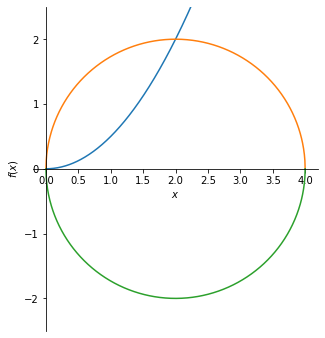

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a, b = 2, 4
kreis_oben = sqrt(Rational(b, 2)**2 - (x - Rational(b, 2))**2)
plot(x**2 / a, kreis_oben, -kreis_oben, (x, 0, b), aspect_ratio=(1, 1), ylim=(-2.5, 2.5));
```

</details>

#### Aufgabe 1.3

Bestimme für x³ + 9x = 18 die Parameter a = √p und b = q/p und die Lösung näherungsweise (4 Ziffern).

**Erwartete Ausgabe:**

$\displaystyle 3$

$\displaystyle 2$

$\displaystyle 1.57$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
pp, qq = 9, 18
display(sqrt(pp), Rational(qq, pp))
N(real_roots(x**3 + pp*x - qq)[0], 4)
```

</details>

#### Aufgabe 1.4

Zeichne die Parabel x² = 3y und den Kreis (x − 1)² + y² = 1 für x³ + 9x = 18 mit `kurve` in ein Bild (0 ≤ x ≤ 2, −1,2 ≤ y ≤ 1,2).

**Erwartete Ausgabe:**



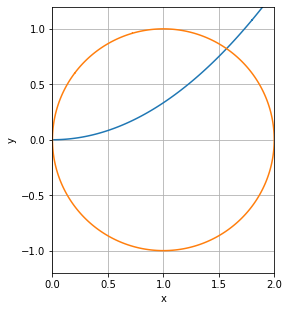

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve(Eq(x**2, 3*y), Eq((x - 1)**2 + y**2, 1), xb=(0, 2), yb=(-1.2, 1.2))
```

</details>

## 2. Wie viele Lösungen hat eine kubische Gleichung?

#### Graph und Diskriminante

Jede kubische Gleichung lässt sich durch eine Verschiebung x → x − b/3 auf die **reduzierte Form** x³ + p·x + q = 0 bringen.
Der Graph von f(x) = x³ + px + q kommt von −∞ und geht nach +∞, deshalb gibt es **mindestens eine** reelle Lösung, höchstens drei.

- `count_roots(polynom)` zählt die reellen Nullstellen, `real_roots(polynom)` gibt sie aus.
- Die **Diskriminante** Δ = −4p³ − 27q² (`discriminant(polynom, x)`) entscheidet: Δ > 0 drei verschiedene, Δ = 0 mehrfache, Δ < 0 eine reelle Lösung.

In [ ]:
for pp, qq in [(-3, 1), (-3, 2), (-3, 3)]:
    f = x**3 + pp*x + qq
    print(f, '  Anzahl:', count_roots(f), '  Diskriminante:', discriminant(f, x))
plot(x**3 - 3*x + 1, x**3 - 3*x + 2, x**3 - 3*x + 3, (x, -2.5, 2), ylim=(-3, 6), legend=True);

#### Aufgabe 2.1

Gib die Anzahl der reellen Lösungen und die Diskriminante von x³ − 6x + 2 = 0 aus.

**Erwartete Ausgabe:**

$\displaystyle 3$

$\displaystyle 756$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
f = x**3 - 6*x + 2
display(count_roots(f))
discriminant(f, x)
```

</details>

#### Aufgabe 2.2

Gib die allgemeine Diskriminante von x³ + px + q aus.

**Erwartete Ausgabe:**

$\displaystyle - 4 p^{3} - 27 q^{2}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
discriminant(x**3 + p*x + q, x)
```

</details>

#### Aufgabe 2.3

Für welche q hat x³ − 3x + q = 0 genau zwei verschiedene Lösungen (Diskriminante 0)? Gib die q-Werte und für jedes die Lösungen aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  2\right]$

$\displaystyle \left[ \left[ -1, \  2\right], \  \left[ -2, \  1\right]\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
qs = solve(discriminant(x**3 - 3*x + q, x), q)
display(qs)
[solve(x**3 - 3*x + w, x) for w in qs]
```

</details>

#### Aufgabe 2.4

Für welche q hat x³ − 3x + q = 0 drei verschiedene reelle Lösungen? (Lösungsmenge von Δ > 0 über ℝ)

**Erwartete Ausgabe:**

$\displaystyle \left(-2, 2\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solveset(discriminant(x**3 - 3*x + q, x) > 0, q, S.Reals)
```

</details>

#### Aufgabe 2.5

Bringe x³ + 6x² + 9x + 4 = 0 auf die reduzierte Form: Setze x = t − 2 ein (b/3 = 2) und multipliziere aus. Gib die reduzierte Gleichung und ihre Lösungen
in t aus und dann die Lösungen in x.

**Erwartete Ausgabe:**

$\displaystyle t^{3} - 3 t + 2$

$\displaystyle \left[ -2, \  1\right]$

$\displaystyle \left[ -4, \  -1\right]$

In [ ]:
t = symbols('t')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t = symbols('t')
red = expand((t - 2)**3 + 6*(t - 2)**2 + 9*(t - 2) + 4)
display(red)
lt = solve(red, t)
display(lt)
[w - 2 for w in lt]
```

</details>

#### Aufgabe 2.6

Zeichne in der p-q-Ebene die Kurve 4p³ + 27q² = 0 (`kurve` mit `var=(p, q)`, −4 ≤ p ≤ 1, −3 ≤ q ≤ 3). Auf der linken Seite zwischen den Ästen liegen
die Gleichungen mit drei reellen Lösungen.

**Erwartete Ausgabe:**



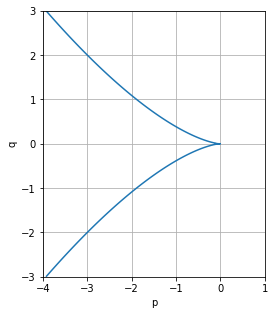

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve(Eq(4*p**3 + 27*q**2, 0), xb=(-4, 1), yb=(-3, 3), var=(p, q))
```

</details>

#### Aufgabe 2.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.
```python
display(count_roots(x**3 - x))
display(count_roots(x**3 + x))
count_roots(x**3)
```

In [ ]:
display(count_roots(x**3 - x))
display(count_roots(x**3 + x))
count_roots(x**3)

## 3. Die Formel von Cardano

#### x = ∛(−q/2 + √D) + ∛(−q/2 − √D)

Für die reduzierte Gleichung x³ + px + q = 0 mit D = (q/2)² + (p/3)³ ≥ 0 liefert die **Formel von Cardano** eine Lösung:

x = ∛(−q/2 + √D) + ∛(−q/2 − √D)

**Achtung:** In sympy ist `cbrt(-8)` nicht −2, sondern eine komplexe Kubikwurzel. Für die **reelle** Kubikwurzel gibt es `real_root(a, 3)`.

Beispiel (Cardano selbst): x³ + 6x = 20.

In [ ]:
pp, qq = 6, -20
D = (Rational(qq, 2))**2 + (Rational(pp, 3))**3
display(D)
x1 = real_root(-Rational(qq, 2) + sqrt(D), 3) + real_root(-Rational(qq, 2) - sqrt(D), 3)
display(x1)
display(N(x1))
display(N(cbrt(-8)), real_root(-8, 3))
solve(x**3 + pp*x + qq, x)

#### Aufgabe 3.1

Schreibe eine Funktion `cardano(pp, qq)`, die D und die Lösung nach der Formel von Cardano (mit `real_root`) als Paar zurückgibt (Zahlen mit `Rational`). Teste mit x³ + 6x − 20 = 0
und gib die Lösung mit `N()` aus.

**Erwartete Ausgabe:**

$\displaystyle 108$

$\displaystyle 2.0$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def cardano(pp, qq):
    D = Rational(qq, 2)**2 + Rational(pp, 3)**3
    return D, real_root(-Rational(qq, 2) + sqrt(D), 3) + real_root(-Rational(qq, 2) - sqrt(D), 3)

D, x1 = cardano(6, -20)
display(D)
N(x1)
```

</details>

#### Aufgabe 3.2

Löse x³ + 3x − 4 = 0 mit der Formel von Cardano (Funktion von oben). Gib D und die Lösung mit 10 Ziffern aus und prüfe, dass x = 1 eine Lösung ist.

**Erwartete Ausgabe:**

$\displaystyle 5$

$\displaystyle 1.0$

```
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
def cardano(pp, qq):
    D = Rational(qq, 2)**2 + Rational(pp, 3)**3
    return D, real_root(-Rational(qq, 2) + sqrt(D), 3) + real_root(-Rational(qq, 2) - sqrt(D), 3)

D, x1 = cardano(3, -4)
display(D, N(x1, 10))
(1**3 + 3*1 - 4) == 0
```

</details>

#### Aufgabe 3.3

Prüfe die Formel von Cardano allgemein: Setze u = ∛(−q/2 + √D) und v = ∛(−q/2 − √D). Zeige mit `expand`, dass u³ + v³ = −q und u³ · v³ = −(p/3)³ ist
(setze u³ und v³ direkt als −q/2 ± √D ein).

**Erwartete Ausgabe:**

$\displaystyle - q$

$\displaystyle - \frac{p^{3}}{27}$

In [ ]:
D = (q / 2)**2 + (p / 3)**3
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
D = (q / 2)**2 + (p / 3)**3
u3 = -q / 2 + sqrt(D)
v3 = -q / 2 - sqrt(D)
display(expand(u3 + v3))
expand(u3 * v3)
```

</details>

#### Aufgabe 3.4

**Al-Chwarizmi** löste quadratische Gleichungen x² + px = q mit „quadratischer Ergänzung“ als Flächen: x = √((p/2)² + q) − p/2. Löse x² + 10x = 39 so
und vergleiche mit `solve`.

**Erwartete Ausgabe:**

$\displaystyle 3$

$\displaystyle \left[ -13, \  3\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
pp, qq = 10, 39
display(sqrt(Rational(pp, 2)**2 + qq) - Rational(pp, 2))
solve(x**2 + pp*x - qq, x)
```

</details>

## 4. Warum man komplexe Zahlen braucht

#### Bombellis Beispiel: x³ = 15x + 4

Die Gleichung x³ − 15x − 4 = 0 hat die Lösung x = 4 (Probe!) und noch zwei weitere reelle. Cardanos Formel liefert aber
D = (−2)² + (−5)³ = −121 < 0, also eine Wurzel aus einer **negativen** Zahl: x = ∛(2 + √−121) + ∛(2 − √−121).

Bombelli (1572) rechnete einfach weiter mit √−121 = 11i. Es gilt (2 + i)³ = 2 + 11i und (2 − i)³ = 2 − 11i, also
x = (2 + i) + (2 − i) = 4. Der Umweg über die komplexen Zahlen führt zu einer reellen Lösung, obwohl es **ohne** ihn nicht geht
(„casus irreducibilis“: drei reelle Lösungen, aber D < 0).

Mit `N(..., chop=True)` werden winzige Rundungsreste im Imaginärteil weggelassen.

In [ ]:
display(Rational(-4, 2)**2 + Rational(-15, 3)**3)
display(sqrt(-121))
display(expand((2 + I)**3), expand((2 - I)**3))
display((2 + I) + (2 - I))
display(real_roots(x**3 - 15*x - 4))
[N(s, 5, chop=True) for s in solve(z**3 - 15*z - 4, z)]

#### Aufgabe 4.1

Berechne D für x³ − 6x − 4 = 0 und gib die reellen Lösungen aus.

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle -4$

$\displaystyle \left[ -2, \  1 - \sqrt{3}, \  1 + \sqrt{3}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Rational(-4, 2)**2 + Rational(-6, 3)**3)
real_roots(x**3 - 6*x - 4)
```

</details>

#### Aufgabe 4.2

Für x³ − 6x − 4 = 0 liefert Cardano x = ∛(2 + 2i) + ∛(2 − 2i). Prüfe: (−1 + i)³ = 2 + 2i. Gib (−1 + i)³ und (−1 − i)³ ausmultipliziert aus
und dann die Summe (−1 + i) + (−1 − i).

**Erwartete Ausgabe:**

$\displaystyle 2 + 2 i$

$\displaystyle 2 - 2 i$

$\displaystyle -2$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(expand((-1 + I)**3), expand((-1 - I)**3))
(-1 + I) + (-1 - I)
```

</details>

#### Aufgabe 4.3

Gib für x³ − 3x + 1 = 0 die Diskriminante D nach Cardano, die Anzahl der reellen Lösungen und alle Lösungen mit 5 Ziffern aus (`solve` mit z, `N` mit `chop=True`).

*Schreibe Brüche und Kommazahlen mit `Rational`, z. B. `Rational(1, 6)` oder `Rational('0.5')`.*

**Erwartete Ausgabe:**

$\displaystyle - \frac{3}{4}$

$\displaystyle 3$

$\displaystyle \left[ 0.3473, \  1.5321, \  -1.8794\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(Rational(1, 2)**2 + Rational(-3, 3)**3)
display(count_roots(x**3 - 3*x + 1))
[N(s, 5, chop=True) for s in solve(z**3 - 3*z + 1, z)]
```

</details>

#### Aufgabe 4.4

Bestimme alle Lösungen von z³ + z + 10 = 0 (eine reelle, zwei komplexe) und zeichne sie als Punkte in die Gaußsche Zahlenebene.

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  1 - 2 i, \  1 + 2 i\right]$

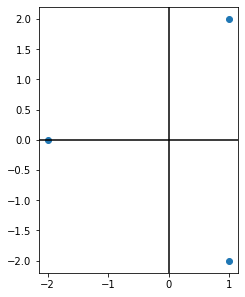

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve(z**3 + z + 10, z)
display(l)
plt.plot([float(re(s)) for s in l], [float(im(s)) for s in l], 'o')
plt.axhline(0, color='black')
plt.axvline(0, color='black')
plt.gca().set_aspect('equal')
plt.show()
```

</details>

## 5. Satz von Vieta und nichtlineare Gleichungssysteme

#### Summe und Produkt der Lösungen

**Satz von Vieta:** Hat x² + px + q = 0 die Lösungen x₁, x₂, dann gilt x₁ + x₂ = −p und x₁ · x₂ = q.
Bei kubischen Gleichungen x³ + ax² + bx + c = 0: x₁ + x₂ + x₃ = −a, x₁x₂ + x₁x₃ + x₂x₃ = b, x₁x₂x₃ = −c.

Umgekehrt: Sucht man zwei Zahlen mit gegebener Summe s und gegebenem Produkt P (das **nichtlineare** System z + w = s, z · w = P),
dann sind z und w die Lösungen von t² − s·t + P = 0. Ist die Diskriminante negativ, sind die Lösungen **komplex konjugiert**.

In [ ]:
display(solve([Eq(z + w, 5), Eq(z * w, 6)], [z, w]))
l = solve([Eq(z + w, 2), Eq(z * w, 5)], [z, w])
display(l)
t_ = symbols('t')
solve(t_**2 - 2*t_ + 5, t_)

#### Aufgabe 5.1

Prüfe den Satz von Vieta für x² − 7x + 10 = 0: Gib die Lösungen, ihre Summe und ihr Produkt aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ 2, \  5\right]$

$\displaystyle \left( 7, \  10\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve(x**2 - 7*x + 10, x)
display(l)
(l[0] + l[1], l[0] * l[1])
```

</details>

#### Aufgabe 5.2

Prüfe den Satz von Vieta für die kubische Gleichung x³ − 6x² + 11x − 6 = 0 (Summe, Summe der Zweierprodukte, Produkt der drei Lösungen).

**Erwartete Ausgabe:**

$\displaystyle \left( 6, \  11, \  6\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
a1, a2, a3 = solve(x**3 - 6*x**2 + 11*x - 6, x)
(a1 + a2 + a3, a1*a2 + a1*a3 + a2*a3, a1*a2*a3)
```

</details>

#### Aufgabe 5.3

Löse das System z + w = 4, z · w = 13 und zeichne die Lösungen z in die Gaußsche Zahlenebene.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 2 + 3 i, \  2 - 3 i\right), \  \left( 2 - 3 i, \  2 + 3 i\right)\right]$

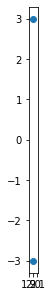

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve([Eq(z + w, 4), Eq(z * w, 13)], [z, w])
display(l)
plt.plot([float(re(s[0])) for s in l], [float(im(s[0])) for s in l], 'o')
plt.gca().set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 5.4

Löse das System x² + y² = 25, x · y = 12 (reell) und gib die Lösungspaare aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( -4, \  -3\right), \  \left( -3, \  -4\right), \  \left( 3, \  4\right), \  \left( 4, \  3\right)\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
solve([Eq(x**2 + y**2, 25), Eq(x * y, 12)], [x, y])
```

</details>

#### Aufgabe 5.5

Löse das System x² + y² = 4, x + y = 3 (komplex, mit z und w) und gib die Lösungen aus. Es gibt keine reelle Lösung, weil die Gerade
x + y = 3 den Kreis nicht schneidet: Prüfe, dass ihr Abstand vom Ursprung (3/√2) größer als der Radius 2 ist (Wahrheitswert).

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( \frac{3}{2} + \frac{i}{2}, \  \frac{3}{2} - \frac{i}{2}\right), \  \left( \frac{3}{2} - \frac{i}{2}, \  \frac{3}{2} + \frac{i}{2}\right)\right]$

$\displaystyle \text{True}$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve([Eq(z**2 + w**2, 4), Eq(z + w, 3)], [z, w]))
3 / sqrt(2) > 2
```

</details>

#### Aufgabe 5.6

Stelle eine quadratische Gleichung auf, deren Lösungen 3 + 2i und 3 − 2i sind (nach Vieta: Summe und Produkt berechnen).

**Erwartete Ausgabe:**

$\displaystyle 6$

$\displaystyle 13$

$\displaystyle t^{2} - 6 t + 13$

In [ ]:
t_ = symbols('t')
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
t_ = symbols('t')
s = expand((3 + 2*I) + (3 - 2*I))
P = expand((3 + 2*I) * (3 - 2*I))
display(s, P)
t_**2 - s*t_ + P
```

</details>

## 6. Potenzgleichungen und Fundamentalsatz der Algebra

#### Jede Gleichung n-ten Grades hat n Lösungen

Die **n-ten Einheitswurzeln** (Lösungen von zⁿ = 1) liegen als regelmäßiges n-Eck auf dem Einheitskreis.
Der **Fundamentalsatz der Algebra** (Gauß, 1799) sagt: Jedes Polynom vom Grad n ≥ 1 hat in den komplexen Zahlen genau n Nullstellen
(mit Vielfachheit gezählt). Mit den komplexen Zahlen ist die Frage „Hat die Gleichung eine Lösung?“ also endgültig beantwortet.

Geometrisch: Multiplizieren mit einer Einheitswurzel e^(2πi/n) dreht um 360°/n; deshalb bilden die Lösungen ein regelmäßiges n-Eck.

In [ ]:
l = solve(z**5 - 1, z)
display([N(s, 3, chop=True) for s in l])
plt.plot([float(re(s)) for s in l], [float(im(s)) for s in l], 'o')
plt.gca().set_aspect('equal')
plt.show()

#### Aufgabe 6.1

Löse z³ = 1 und z³ = −1.

**Erwartete Ausgabe:**

$\displaystyle \left[ 1, \  - \frac{1}{2} - \frac{\sqrt{3} i}{2}, \  - \frac{1}{2} + \frac{\sqrt{3} i}{2}\right]$

$\displaystyle \left[ -1, \  \frac{1}{2} - \frac{\sqrt{3} i}{2}, \  \frac{1}{2} + \frac{\sqrt{3} i}{2}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve(z**3 - 1, z))
solve(z**3 + 1, z)
```

</details>

#### Aufgabe 6.2

Löse z⁴ = 16 und zeichne die Lösungen in die Zahlenebene.

**Erwartete Ausgabe:**

$\displaystyle \left[ -2, \  2, \  - 2 i, \  2 i\right]$

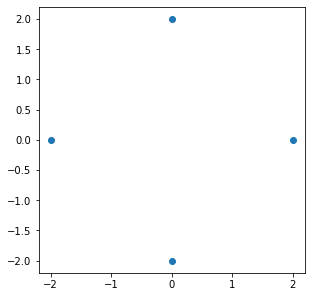

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
l = solve(z**4 - 16, z)
display(l)
plt.plot([float(re(s)) for s in l], [float(im(s)) for s in l], 'o')
plt.gca().set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 6.3

Prüfe den Fundamentalsatz an Beispielen: Gib für z⁷ − 1, z⁴ + z + 1 und (z − 1)³(z + 2) die Anzahl der Nullstellen mit Vielfachheit aus
(`roots(...)` gibt ein Dictionary Nullstelle → Vielfachheit; summiere die Vielfachheiten mit `sum(roots(f).values())`, bei z⁴ + z + 1 mit `Poly(f, z).degree()`).

**Erwartete Ausgabe:**

$\displaystyle 7$

$\displaystyle 4$

$\displaystyle 4$

$\displaystyle 4$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(sum(roots(z**7 - 1, z).values()))
display(Poly(z**4 + z + 1, z).degree(), len(solve(z**4 + z + 1, z)))
sum(roots((z - 1)**3 * (z + 2), z).values())
```

</details>

#### Aufgabe 6.4

Multipliziere die Einheitswurzel ζ = e^(2πi/6) nacheinander mit sich selbst (ζ¹, ..., ζ⁶) und gib die Ergebnisse in der Form a + bi aus.

**Erwartete Ausgabe:**

$\displaystyle \left[ \frac{1}{2} + \frac{\sqrt{3} i}{2}, \  - \frac{1}{2} + \frac{\sqrt{3} i}{2}, \  -1, \  - \frac{1}{2} - \frac{\sqrt{3} i}{2}, \  \frac{1}{2} - \frac{\sqrt{3} i}{2}, \  1\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
zeta = exp(2 * pi * I / 6)
[expand_complex(zeta**k) for k in range(1, 7)]
```

</details>

#### Aufgabe 6.5

Zerlege z³ − 1 in Linearfaktoren (`factor(..., extension=sqrt(3)*I)`).

**Erwartete Ausgabe:**

$\displaystyle \left(z - 1\right) \left(z + \frac{1}{2} - \frac{\sqrt{3} i}{2}\right) \left(z + \frac{1}{2} + \frac{\sqrt{3} i}{2}\right)$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
factor(z**3 - 1, extension=sqrt(3)*I)
```

</details>

## 7. Lösungsmengen als algebraische Kurven

#### Gleichungen in x und y

Die Lösungsmenge einer Gleichung mit zwei Variablen x und y ist eine **Kurve** in der Ebene, z. B. x² + y² = 1 (Kreis).
Ist die Gleichung ein Polynom in x und y, heißt die Kurve **algebraisch**. Die Hilfsfunktion `kurve` aus der Setup-Zelle zeichnet sie,
auch wenn man nicht nach y auflösen kann.

Bekannte Beispiele: das **Kartesische Blatt** x³ + y³ = 3xy, die **Lemniskate** (x² + y²)² = 2(x² − y²), **elliptische Kurven** y² = x³ + ax + b.

In [ ]:
kurve(Eq(x**3 + y**3, 3*x*y))
display(Eq(x**3 + y**3, 3*x*y).subs({x: Rational(3, 2), y: Rational(3, 2)}))

#### Aufgabe 7.1

Zeichne die Ellipse x²/9 + y²/4 = 1 mit `kurve` (−4 ≤ x, y ≤ 4).

**Erwartete Ausgabe:**



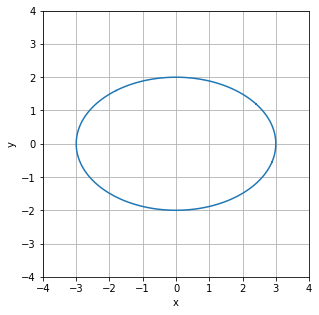

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve(Eq(x**2 / 9 + y**2 / 4, 1), xb=(-4, 4), yb=(-4, 4))
```

</details>

#### Aufgabe 7.2

Zeichne die Lemniskate (x² + y²)² = 2(x² − y²) (−2 ≤ x ≤ 2, −1 ≤ y ≤ 1).

**Erwartete Ausgabe:**



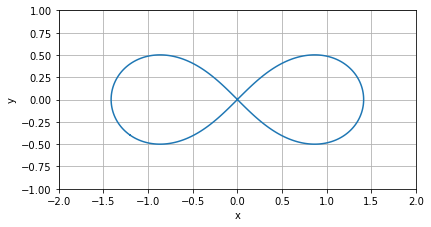

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve(Eq((x**2 + y**2)**2, 2*(x**2 - y**2)), xb=(-2, 2), yb=(-1, 1))
```

</details>

#### Aufgabe 7.3

Zeichne die elliptische Kurve y² = x³ − x (−2 ≤ x ≤ 3, −4 ≤ y ≤ 4).

**Erwartete Ausgabe:**



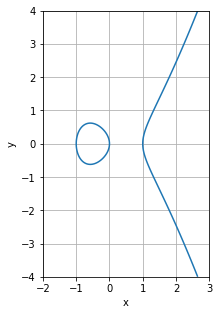

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve(Eq(y**2, x**3 - x), xb=(-2, 3), yb=(-4, 4))
```

</details>

#### Aufgabe 7.4

Prüfe, welche der Punkte (0 | 0), (1 | 0), (2 | √6) und (2 | 3) auf der Kurve y² = x³ − x liegen (Liste von Wahrheitswerten).

**Erwartete Ausgabe:**

$\displaystyle \left[ \text{True}, \  \text{True}, \  \text{True}, \  \text{False}\right]$

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
kurve = Eq(y**2, x**3 - x)
[kurve.subs({x: a, y: b}) for a, b in [(0, 0), (1, 0), (2, sqrt(6)), (2, 3)]]
```

</details>

#### Aufgabe 7.5

Berechne die Schnittpunkte des Kreises x² + y² = 5 mit der Hyperbel x · y = 2 und zeichne beide Kurven in ein Bild (−3 ≤ x, y ≤ 3).

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( -2, \  -1\right), \  \left( -1, \  -2\right), \  \left( 1, \  2\right), \  \left( 2, \  1\right)\right]$

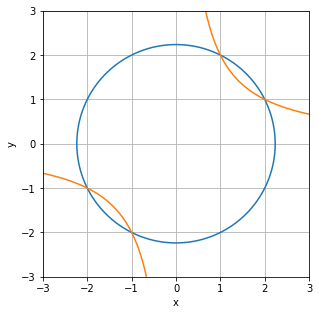

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve([Eq(x**2 + y**2, 5), Eq(x * y, 2)], [x, y]))
kurve(Eq(x**2 + y**2, 5), Eq(x * y, 2))
```

</details>

#### Aufgabe 7.6

Berechne die Schnittpunkte des Kreises x² + y² = 4 mit der Parabel y = x² − 2 und zeichne beide Kurven in ein Bild (−3 ≤ x, y ≤ 3).

**Erwartete Ausgabe:**

$\displaystyle \left[ \left( 0, \  -2\right), \  \left( - \sqrt{3}, \  1\right), \  \left( \sqrt{3}, \  1\right)\right]$

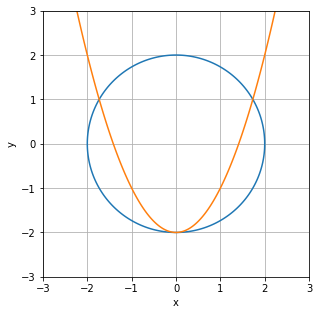

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
display(solve([Eq(x**2 + y**2, 4), Eq(y, x**2 - 2)], [x, y]))
kurve(Eq(x**2 + y**2, 4), Eq(y, x**2 - 2))
```

</details>